In [1]:
import os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Chemins vers les données
DATA_DIR = "../data/chest_xray"

train_dir = os.path.join(DATA_DIR, "train")
val_dir   = os.path.join(DATA_DIR, "val")
test_dir  = os.path.join(DATA_DIR, "test")

print("Train folders :", os.listdir(train_dir))
print("Validation folders :", os.listdir(val_dir))
print("Test folders :", os.listdir(test_dir))



Train folders : ['NORMAL', 'PNEUMONIA']
Validation folders : ['NORMAL', 'PNEUMONIA']
Test folders : ['NORMAL', 'PNEUMONIA']


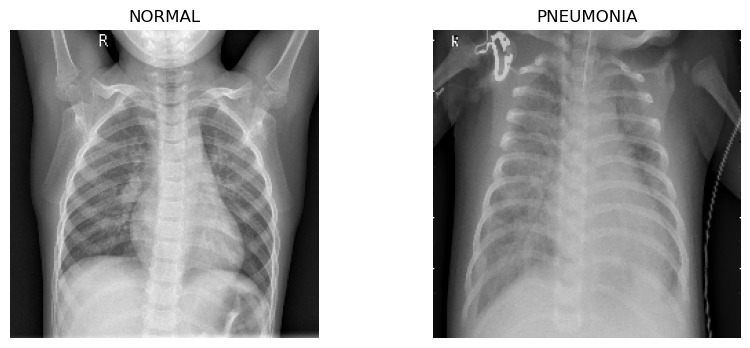

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img

# Afficher quelques images de chaque classe
classes = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(10, 4))

for i, classe in enumerate(classes):
    folder = os.path.join(train_dir, classe)
    img_path = os.path.join(folder, os.listdir(folder)[0])
    
    img = load_img(img_path, target_size=(224, 224))
    
    plt.subplot(1, 2, i + 1)
    plt.imshow(img)
    plt.title(classe)
    plt.axis("off")

plt.show()


In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Paramètres
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Générateur pour l'entraînement (avec normalisation)
train_datagen = ImageDataGenerator(
    rescale=1./255
)

# Générateur pour validation et test
val_test_datagen = ImageDataGenerator(
    rescale=1./255
)

# Chargement des données
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary"
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)


Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


Chargement et exploration du dataset

Dans cette étape, nous nous intéressons à la préparation des données, qui constitue une phase essentielle avant l’entraînement d’un modèle de Deep Learning.
Le dataset utilisé est Chest X-Ray Pneumonia, composé de radiographies thoraciques classées en deux catégories : NORMAL (poumon sain) et PNEUMONIA (poumon atteint de pneumonie).

Les données sont organisées en trois sous-ensembles distincts :

un ensemble d’entraînement (train),

un ensemble de validation (validation),

un ensemble de test (test).

Cette séparation permet d’entraîner le modèle, d’ajuster ses paramètres et d’évaluer ses performances de manière objective.

Exploration et visualisation des images

Une exploration visuelle des images a été réalisée afin de mieux comprendre la nature des données et d’observer les différences entre les radiographies de poumons sains et malades.
Cette étape permet également de vérifier la qualité des images et de s’assurer qu’elles sont exploitables pour l’apprentissage automatique.

Prétraitement des données

Avant l’entraînement du modèle, un prétraitement des images a été appliqué.
Les images ont été redimensionnées à une taille uniforme (224 × 224 pixels) afin de garantir une compatibilité avec les modèles de réseaux de neurones convolutifs.

Une normalisation des pixels a également été effectuée en ramenant les valeurs des pixels dans l’intervalle [0,1]. Cette opération facilite la convergence du modèle et améliore la stabilité de l’apprentissage.

Le chargement des images est réalisé à l’aide de la classe ImageDataGenerator, qui permet de lire automatiquement les images depuis les dossiers et de les fournir au modèle sous forme de lots (batches).

Conclusion

À l’issue de cette étape, les données sont correctement organisées, visualisées et prétraitées.
Elles sont désormais prêtes à être utilisées pour l’entraînement des modèles de Deep Learning dans les étapes suivantes du projet.
